Plan:
Compare 4 automated approaches for follicle-like region annotation in ovarian ultrasound images:

1. Gemini — multimodal foundation model
2. BiomedParse — medical foundation model
3. nnU-Net 2D — supervised segmentation model
4. CR-Semi-derived 2D — adapted supervised segmentation model

All models are evaluated on the same 61 validation images.

The analysis includes qualitative visual assessments and available quantitative metrics.

BiomedParse pseudo-labels are not expert ground truth. Manual assessments represent non-clinical visual plausibility judgments.

In [1]:
# Mount Google Drive and define project paths

from google.colab import drive
from pathlib import Path
import pandas as pd

drive.mount("/content/drive")

PROJECT_DIR = Path(
    "/content/drive/MyDrive/ovarian_ultrasound_vlm"
)

EVALUATION_DIR = PROJECT_DIR / "evaluation"

MANIFEST_PATH = PROJECT_DIR / "image_manifest.csv"

manifest = pd.read_csv(MANIFEST_PATH)

validation = manifest.loc[
    manifest["split"].astype(str).str.strip().str.lower()
    == "validation"
].copy()

assert len(validation) == 61
assert validation["case_id"].is_unique

print("Validation images:", len(validation))
print("Categories:")
print(validation["category"].value_counts())

Mounted at /content/drive
Validation images: 61
Categories:
category
dominant    31
pco         21
normal       9
Name: count, dtype: int64


Mount Google Drive and define project paths

In [3]:
# Load and validate qualitative reviews for all four models.

import pandas as pd
from pathlib import Path

REVIEW_FILES = {
    "Gemini": (
        EVALUATION_DIR
        / "semantic"
        / "gemini_qualitative_review_final.csv"
    ),
    "BiomedParse": (
        EVALUATION_DIR
        / "biomedparse_qualitative"
        / "biomedparse_manual_review.xlsx"
    ),
    "nnU-Net 2D": (
        EVALUATION_DIR
        / "nnunet_2d_qualitative"
        / "nnunet_2d_manual_review_final.csv"
    ),
    "CR-Semi-derived 2D": (
        EVALUATION_DIR
        / "crsemi_2d_qualitative"
        / "crsemi_2d_manual_review_final.csv"
    ),
}

VALID_ASSESSMENTS = ["Good", "Partial", "Poor", "Unclear"]

reviews = {}
expected_ids = set(validation["case_id"])

for model_name, file_path in REVIEW_FILES.items():

    assert file_path.is_file(), (
        f"Missing review file: {file_path}"
    )

    # Read CSV or Excel depending on the file extension.
    if file_path.suffix == ".xlsx":
        # Read the first worksheet regardless of its name.
        df = pd.read_excel(
            file_path,
            sheet_name=0,
            engine="openpyxl",
            keep_default_na=False
        )
    else:
        df = pd.read_csv(
            file_path,
            keep_default_na=False
        )

    required_columns = {
        "case_id",
        "overall_visual_assessment"
    }

    assert required_columns.issubset(df.columns), model_name

    df["case_id"] = df["case_id"].astype(str).str.strip()

    df["overall_visual_assessment"] = (
        df["overall_visual_assessment"]
        .astype(str)
        .str.strip()
    )

    # Verify case IDs and review completeness.
    assert len(df) == 61, model_name
    assert df["case_id"].is_unique, model_name

    assert set(df["case_id"]) == expected_ids, (
        f"Validation case mismatch: {model_name}"
    )

    assert df["overall_visual_assessment"].isin(
        VALID_ASSESSMENTS
    ).all(), f"Invalid assessments: {model_name}"

    reviews[model_name] = df

    print(
        f"{model_name}: "
        f"{len(df)} images, "
        f"all assessments valid"
    )

print("\nAll four models evaluated on the same 61 images.")

Gemini: 61 images, all assessments valid
BiomedParse: 61 images, all assessments valid
nnU-Net 2D: 61 images, all assessments valid
CR-Semi-derived 2D: 61 images, all assessments valid

All four models evaluated on the same 61 images.



Load the completed manual review files for Gemini, BiomedParse,
nnU-Net 2D, and CR-Semi-derived 2D.

Verify that all four evaluations cover the same 61 validation images
and use consistent assessment categories.

,model,Good,Partial,Poor,Unclear,Good + Partial,Good + Partial (%)
0,Gemini,10,19,24,8,29,47.54
1,BiomedParse,7,29,17,8,36,59.02
2,nnU-Net 2D,1,50,8,2,51,83.61
3,CR-Semi-derived 2D,2,51,6,2,53,86.89


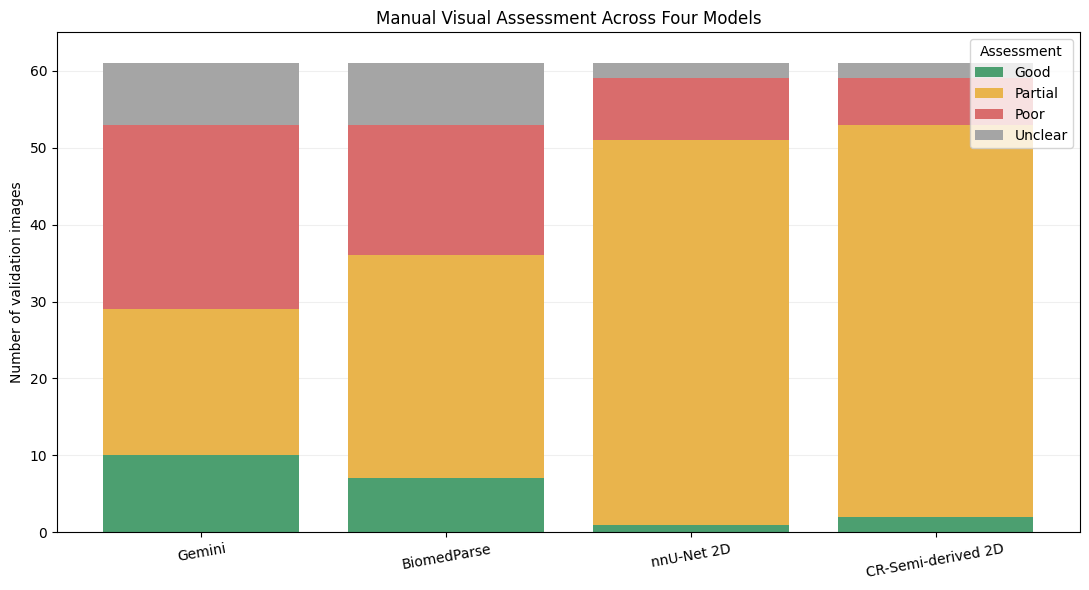

Comparison table: /content/drive/MyDrive/ovarian_ultrasound_vlm/evaluation/cross_model/qualitative_comparison.csv
Comparison figure: /content/drive/MyDrive/ovarian_ultrasound_vlm/evaluation/cross_model/qualitative_comparison.png


In [4]:
# Compare qualitative assessment distributions across all four models.

import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

MODEL_ORDER = [
    "Gemini",
    "BiomedParse",
    "nnU-Net 2D",
    "CR-Semi-derived 2D"
]

ASSESSMENT_ORDER = [
    "Good",
    "Partial",
    "Poor",
    "Unclear"
]

# Count manual assessments for each model.
comparison_records = []

for model_name in MODEL_ORDER:

    df = reviews[model_name]

    counts = (
        df["overall_visual_assessment"]
        .value_counts()
        .reindex(ASSESSMENT_ORDER, fill_value=0)
    )

    record = {"model": model_name}

    for assessment in ASSESSMENT_ORDER:
        record[assessment] = int(counts[assessment])

    record["Good + Partial"] = (
        record["Good"] + record["Partial"]
    )

    record["Good + Partial (%)"] = round(
        record["Good + Partial"] / len(df) * 100,
        2
    )

    comparison_records.append(record)

comparison_df = pd.DataFrame(comparison_records)

assert comparison_df[ASSESSMENT_ORDER].sum(axis=1).eq(61).all()

display(comparison_df)

# Save the comparison table.
COMPARISON_DIR = PROJECT_DIR / "evaluation" / "cross_model"
COMPARISON_DIR.mkdir(parents=True, exist_ok=True)

COMPARISON_CSV = (
    COMPARISON_DIR / "qualitative_comparison.csv"
)

comparison_df.to_csv(COMPARISON_CSV, index=False)

# Plot the distribution of assessments.
colors = {
    "Good": "#4C9F70",
    "Partial": "#E9B44C",
    "Poor": "#D96C6C",
    "Unclear": "#A5A5A5"
}

fig, ax = plt.subplots(figsize=(11, 6))

bottom = np.zeros(len(comparison_df))

for assessment in ASSESSMENT_ORDER:

    values = comparison_df[assessment].to_numpy()

    ax.bar(
        comparison_df["model"],
        values,
        bottom=bottom,
        label=assessment,
        color=colors[assessment]
    )

    bottom += values

ax.set_ylabel("Number of validation images")
ax.set_title("Manual Visual Assessment Across Four Models")
ax.set_ylim(0, 65)

ax.legend(
    title="Assessment",
    loc="upper right"
)

ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)

plt.xticks(rotation=10)
plt.tight_layout()

FIGURE_PATH = (
    COMPARISON_DIR / "qualitative_comparison.png"
)

fig.savefig(
    FIGURE_PATH,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

print("Comparison table:", COMPARISON_CSV)
print("Comparison figure:", FIGURE_PATH)

Compare the distributions of manual visual assessments across the
four models on the same 61 validation images.

The assessments reflect non-clinical visual plausibility rather
than segmentation accuracy against expert ground truth.

In [5]:
# Calculate segmentation agreement with BiomedParse pseudo-labels.

import numpy as np
import pandas as pd
from pathlib import Path
from PIL import Image

PREDICTION_DIRS = {
    "nnU-Net 2D": (
        PROJECT_DIR / "predictions" / "nnunet_2d_validation"
    ),
    "CR-Semi-derived 2D": (
        PROJECT_DIR / "predictions" / "crsemi_2d_validation"
    )
}

QUANTITATIVE_DIR = (
    PROJECT_DIR / "evaluation" / "cross_model" / "quantitative"
)

QUANTITATIVE_DIR.mkdir(parents=True, exist_ok=True)


def calculate_segmentation_metrics(prediction, reference):
    """Calculate pixel-wise agreement for two binary masks."""

    prediction = prediction.astype(bool)
    reference = reference.astype(bool)

    tp = int(np.logical_and(prediction, reference).sum())
    fp = int(np.logical_and(prediction, ~reference).sum())
    fn = int(np.logical_and(~prediction, reference).sum())

    prediction_pixels = tp + fp
    reference_pixels = tp + fn
    union = tp + fp + fn

    # Perfect agreement when both masks are empty.
    dice = (
        2 * tp / (prediction_pixels + reference_pixels)
        if prediction_pixels + reference_pixels > 0
        else 1.0
    )

    iou = tp / union if union > 0 else 1.0

    # Undefined denominators are recorded as NaN.
    precision = (
        tp / prediction_pixels
        if prediction_pixels > 0
        else np.nan
    )

    recall = (
        tp / reference_pixels
        if reference_pixels > 0
        else np.nan
    )

    return {
        "dice": dice,
        "iou": iou,
        "precision": precision,
        "recall": recall,
        "prediction_pixels": prediction_pixels,
        "reference_pixels": reference_pixels,
        "both_empty": prediction_pixels == 0 and reference_pixels == 0
    }


metric_records = []

for model_name, prediction_dir in PREDICTION_DIRS.items():

    assert prediction_dir.is_dir(), prediction_dir

    for row in validation.itertuples(index=False):

        case_id = row.case_id

        prediction_path = prediction_dir / f"{case_id}.png"
        reference_path = Path(row.pseudo_label_path)

        assert prediction_path.is_file(), prediction_path
        assert reference_path.is_file(), reference_path

        prediction = np.asarray(Image.open(prediction_path))
        reference = np.asarray(Image.open(reference_path))

        assert prediction.ndim == 2, case_id
        assert reference.ndim == 2, case_id

        assert prediction.shape == reference.shape, (
            f"Shape mismatch for {case_id}: "
            f"{prediction.shape} vs {reference.shape}"
        )

        assert np.isin(prediction, [0, 1]).all(), case_id
        assert np.isin(reference, [0, 1]).all(), case_id

        metrics = calculate_segmentation_metrics(
            prediction == 1,
            reference == 1
        )

        metric_records.append({
            "model": model_name,
            "case_id": case_id,
            "category": row.category,
            **metrics
        })

# Build the per-image results table.
metrics_df = pd.DataFrame(metric_records)

assert len(metrics_df) == 122
assert not metrics_df.duplicated(["model", "case_id"]).any()

# Aggregate metrics across the 61 images per model.
summary_df = (
    metrics_df
    .groupby("model", as_index=False)
    .agg(
        mean_dice=("dice", "mean"),
        mean_iou=("iou", "mean"),
        mean_precision=("precision", "mean"),
        mean_recall=("recall", "mean"),
        empty_mask_pairs=("both_empty", "sum"),
        images=("case_id", "count")
    )
)

# Round displayed values without altering the saved raw metrics.
print("Per-model segmentation agreement:")
display(summary_df.round(4))

print("\nPer-image results:")
display(metrics_df.head())

# Save quantitative results.
METRICS_CSV = QUANTITATIVE_DIR / "segmentation_metrics_per_image.csv"
SUMMARY_CSV = QUANTITATIVE_DIR / "segmentation_metrics_summary.csv"

metrics_df.to_csv(METRICS_CSV, index=False)
summary_df.to_csv(SUMMARY_CSV, index=False)

print("\nSaved files:")
print(METRICS_CSV)
print(SUMMARY_CSV)

Per-model segmentation agreement:


,model,mean_dice,mean_iou,mean_precision,mean_recall,empty_mask_pairs,images
0,CR-Semi-derived 2D,0.4313,0.3247,0.4170,0.5145,0,61
1,nnU-Net 2D,0.4141,0.3254,0.4247,0.4740,0,61



Per-image results:


,model,case_id,category,dice,iou,precision,recall,prediction_pixels,reference_pixels,both_empty
0,nnU-Net 2D,dominant_0011,dominant,0.801889,0.669294,1.000000,0.669294,10868,16238,False
1,nnU-Net 2D,dominant_0012,dominant,0.000000,0.000000,0.000000,0.000000,7126,5733,False
2,nnU-Net 2D,dominant_0017,dominant,0.000000,0.000000,0.000000,0.000000,19111,16000,False
3,nnU-Net 2D,dominant_0019,dominant,0.273698,0.158546,0.195295,0.457279,16662,7116,False
4,nnU-Net 2D,dominant_0021,dominant,0.583474,0.411905,0.651701,0.528179,21427,26438,False



Saved files:
/content/drive/MyDrive/ovarian_ultrasound_vlm/evaluation/cross_model/quantitative/segmentation_metrics_per_image.csv
/content/drive/MyDrive/ovarian_ultrasound_vlm/evaluation/cross_model/quantitative/segmentation_metrics_summary.csv


Evaluate nnU-Net 2D and CR-Semi-derived 2D segmentation masks
against BiomedParse pseudo-labels on the same 61 validation images.

Metrics:
- Dice coefficient
- Intersection over Union (IoU)
- Pixel-wise precision
- Pixel-wise recall

These metrics measure agreement with pseudo-labels, not
segmentation accuracy against expert ground truth.

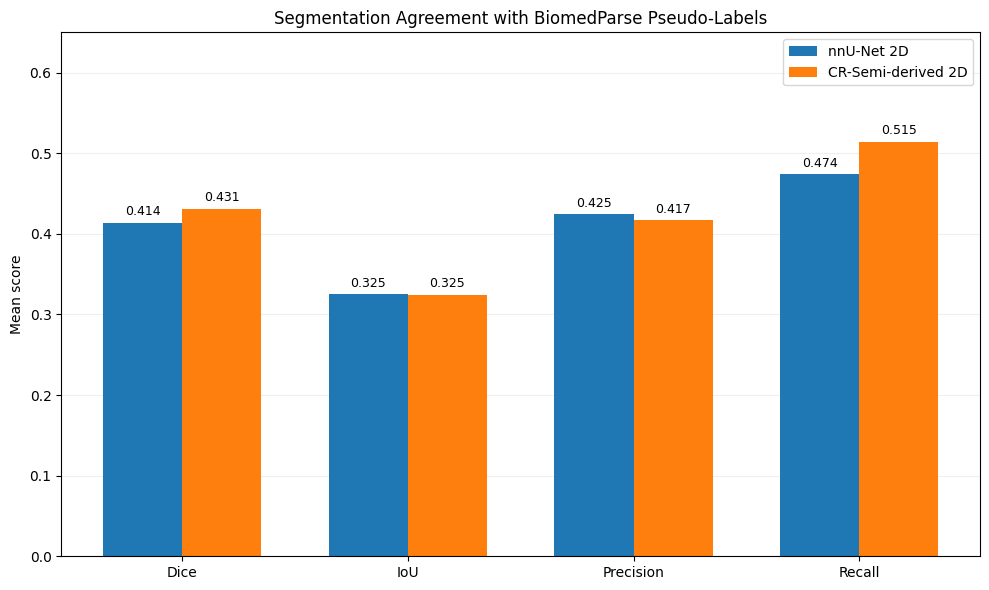

Figure saved: /content/drive/MyDrive/ovarian_ultrasound_vlm/evaluation/cross_model/quantitative/segmentation_metrics_comparison.png


In [6]:
# Visualize quantitative agreement with BiomedParse pseudo-labels.

import matplotlib.pyplot as plt
import numpy as np

metrics = {
    "Dice": "mean_dice",
    "IoU": "mean_iou",
    "Precision": "mean_precision",
    "Recall": "mean_recall"
}

model_order = ["nnU-Net 2D", "CR-Semi-derived 2D"]

plot_df = summary_df.set_index("model").loc[model_order]

x = np.arange(len(metrics))
width = 0.35

fig, ax = plt.subplots(figsize=(10, 6))

for i, model_name in enumerate(model_order):
    values = plot_df[list(metrics.values())].loc[model_name].to_numpy()

    bars = ax.bar(
        x + (i - 0.5) * width,
        values,
        width,
        label=model_name
    )

    ax.bar_label(
        bars,
        fmt="%.3f",
        padding=3,
        fontsize=9
    )

ax.set_xticks(x)
ax.set_xticklabels(list(metrics.keys()))
ax.set_ylim(0, 0.65)

ax.set_ylabel("Mean score")
ax.set_title("Segmentation Agreement with BiomedParse Pseudo-Labels")
ax.legend()

ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)

plt.tight_layout()

FIGURE_PATH = (
    QUANTITATIVE_DIR / "segmentation_metrics_comparison.png"
)

fig.savefig(
    FIGURE_PATH,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

print("Figure saved:", FIGURE_PATH)

Visualize mean Dice, IoU, precision, and recall for nnU-Net 2D
and CR-Semi-derived 2D against BiomedParse pseudo-labels.

These metrics represent pseudo-label agreement rather than
expert-validated segmentation accuracy.

BiomedParse serves as the pseudo-reference and is therefore not included as an evaluated model. Reported values measure agreement with pseudo-labels rather than segmentation accuracy against expert-annotated ground truth

In [9]:
# Summarize Gemini spatial localization and region counting metrics.

import numpy as np
import pandas as pd

spatial_df = gemini_results["spatial"].copy()
count_df = gemini_results["count"].copy()

expected_ids = set(validation["case_id"])

# Verify that both files cover the same validation images.
for name, df in [
    ("Spatial", spatial_df),
    ("Count", count_df)
]:
    assert len(df) == 61, name
    assert df["case_id"].is_unique, name
    assert set(df["case_id"]) == expected_ids, name

# Validate spatial matching counts.
assert (
    spatial_df["matched_regions"]
    + spatial_df["unmatched_gemini"]
    == spatial_df["gemini_count"]
).all()

assert (
    spatial_df["matched_regions"]
    + spatial_df["unmatched_biomedparse"]
    == spatial_df["biomedparse_count"]
).all()

# Aggregate matches over all 61 images.
tp = int(spatial_df["matched_regions"].sum())
fp = int(spatial_df["unmatched_gemini"].sum())
fn = int(spatial_df["unmatched_biomedparse"].sum())

spatial_precision = tp / (tp + fp) if tp + fp > 0 else np.nan
spatial_recall = tp / (tp + fn) if tp + fn > 0 else np.nan

spatial_f1 = (
    2 * tp / (2 * tp + fp + fn)
    if 2 * tp + fp + fn > 0
    else np.nan
)

# IoU is defined only for images with matched regions.
matched_iou = spatial_df.loc[
    spatial_df["matched_regions"] > 0,
    "mean_matched_iou"
]

# Check consistency between spatial and count tables.
merged_counts = spatial_df[
    ["case_id", "gemini_count", "biomedparse_count"]
].merge(
    count_df[
        ["case_id", "gemini_count", "biomedparse_count", "absolute_error"]
    ],
    on="case_id",
    suffixes=("_spatial", "_count"),
    validate="one_to_one"
)

assert (
    merged_counts["gemini_count_spatial"]
    == merged_counts["gemini_count_count"]
).all()

assert (
    merged_counts["biomedparse_count_spatial"]
    == merged_counts["biomedparse_count_count"]
).all()

assert (
    count_df["absolute_error"]
    == (
        count_df["gemini_count"]
        - count_df["biomedparse_count"]
    ).abs()
).all()

count_mae = count_df["absolute_error"].mean()

# Summarize available metrics.
gemini_summary = pd.DataFrame([{
    "model": "Gemini",
    "images": len(spatial_df),
    "matched_regions": tp,
    "unmatched_gemini": fp,
    "unmatched_biomedparse": fn,
    "spatial_precision": spatial_precision,
    "spatial_recall": spatial_recall,
    "spatial_f1": spatial_f1,
    "mean_matched_iou": matched_iou.mean(),
    "images_with_matches": int(
        (spatial_df["matched_regions"] > 0).sum()
    ),
    "count_mae": count_mae
}])

# Save without modifying the original evaluation files.
GEMINI_SUMMARY_PATH = (
    COMPARISON_DIR / "gemini_quantitative_summary.csv"
)

gemini_summary.to_csv(GEMINI_SUMMARY_PATH, index=False)

print("Gemini quantitative summary:")
display(gemini_summary.round(4))

print("\nSaved to:", GEMINI_SUMMARY_PATH)

Gemini quantitative summary:


,model,images,matched_regions,unmatched_gemini,unmatched_biomedparse,spatial_precision,spatial_recall,spatial_f1,mean_matched_iou,images_with_matches,count_mae
0,Gemini,61,7,136,72,0.049,0.0886,0.0631,0.6326,7,1.8361



Saved to: /content/drive/MyDrive/ovarian_ultrasound_vlm/evaluation/cross_model/gemini_quantitative_summary.csv


Calculate spatial localization F1, precision, recall, matched-region
IoU, and region-counting error from the previously saved main
validation results.

BiomedParse pseudo-labels serve as the reference. These metrics
do not represent performance against expert ground truth.

In [10]:
# Consolidate qualitative and quantitative results for all four models.

import numpy as np
import pandas as pd

FINAL_COMPARISON_DIR = (
    PROJECT_DIR / "evaluation" / "cross_model"
)

FINAL_COMPARISON_DIR.mkdir(parents=True, exist_ok=True)

# Start with the qualitative results shared by all four models.
final_comparison = comparison_df.copy()

# Add quantitative metric columns.
metric_columns = [
    "mean_dice",
    "mean_iou",
    "mean_precision",
    "mean_recall",
    "spatial_f1",
    "mean_matched_iou",
    "count_mae"
]

for column in metric_columns:
    final_comparison[column] = np.nan

# Add segmentation metrics for nnU-Net and CR-Semi.
for _, row in summary_df.iterrows():

    model_name = row["model"]
    mask = final_comparison["model"] == model_name

    for metric in [
        "mean_dice",
        "mean_iou",
        "mean_precision",
        "mean_recall"
    ]:
        final_comparison.loc[mask, metric] = row[metric]

# Add Gemini-specific quantitative metrics.
gemini_row = gemini_summary.iloc[0]
gemini_mask = final_comparison["model"] == "Gemini"

for metric in [
    "spatial_f1",
    "mean_matched_iou",
    "count_mae"
]:
    final_comparison.loc[gemini_mask, metric] = gemini_row[metric]

# Explain how each model was evaluated quantitatively.
evaluation_roles = {
    "Gemini": "Bounding-box localization vs BiomedParse",
    "BiomedParse": "Pseudo-reference; no self-comparison",
    "nnU-Net 2D": "Pixel-wise agreement vs BiomedParse",
    "CR-Semi-derived 2D": "Pixel-wise agreement vs BiomedParse"
}

final_comparison["quantitative_evaluation"] = (
    final_comparison["model"].map(evaluation_roles)
)

assert len(final_comparison) == 4
assert final_comparison["model"].is_unique
assert final_comparison[
    ["Good", "Partial", "Poor", "Unclear"]
].sum(axis=1).eq(61).all()

# Save the complete comparison.
FINAL_CSV = (
    FINAL_COMPARISON_DIR / "final_cross_model_comparison.csv"
)

final_comparison.to_csv(FINAL_CSV, index=False)

print("Final cross-model comparison:")
display(final_comparison.round(4).fillna("—"))

print("\nSaved to:", FINAL_CSV)

Final cross-model comparison:


,model,Good,Partial,Poor,Unclear,Good + Partial,Good + Partial (%),mean_dice,mean_iou,mean_precision,mean_recall,spatial_f1,mean_matched_iou,count_mae,quantitative_evaluation
0,Gemini,10,19,24,8,29,47.54,—,—,—,—,0.0631,0.6326,1.8361,Bounding-box localization vs BiomedParse
1,BiomedParse,7,29,17,8,36,59.02,—,—,—,—,—,—,—,Pseudo-reference; no self-comparison
2,nnU-Net 2D,1,50,8,2,51,83.61,0.4141,0.3254,0.4247,0.474,—,—,—,Pixel-wise agreement vs BiomedParse
3,CR-Semi-derived 2D,2,51,6,2,53,86.89,0.4313,0.3247,0.417,0.5145,—,—,—,Pixel-wise agreement vs BiomedParse



Saved to: /content/drive/MyDrive/ovarian_ultrasound_vlm/evaluation/cross_model/final_cross_model_comparison.csv


Combine manual visual assessments and quantitative evaluation results
for all four approaches.

Pixel-wise segmentation metrics and bounding-box localization metrics
are reported separately because they are not directly comparable.

BiomedParse serves as the pseudo-reference for quantitative evaluation.

Category-wise segmentation agreement:


,model,category,images,mean_dice,mean_iou,mean_precision,mean_recall
0,CR-Semi-derived 2D,dominant,31,0.3269,0.2272,0.3110,0.4141
1,nnU-Net 2D,dominant,31,0.3212,0.2500,0.3410,0.3458
2,CR-Semi-derived 2D,normal,9,0.4922,0.3439,0.4972,0.6535
3,nnU-Net 2D,normal,9,0.3959,0.2661,0.4414,0.5532
4,CR-Semi-derived 2D,pco,21,0.5593,0.4605,0.5392,0.6032
5,nnU-Net 2D,pco,21,0.5590,0.4620,0.5371,0.6292


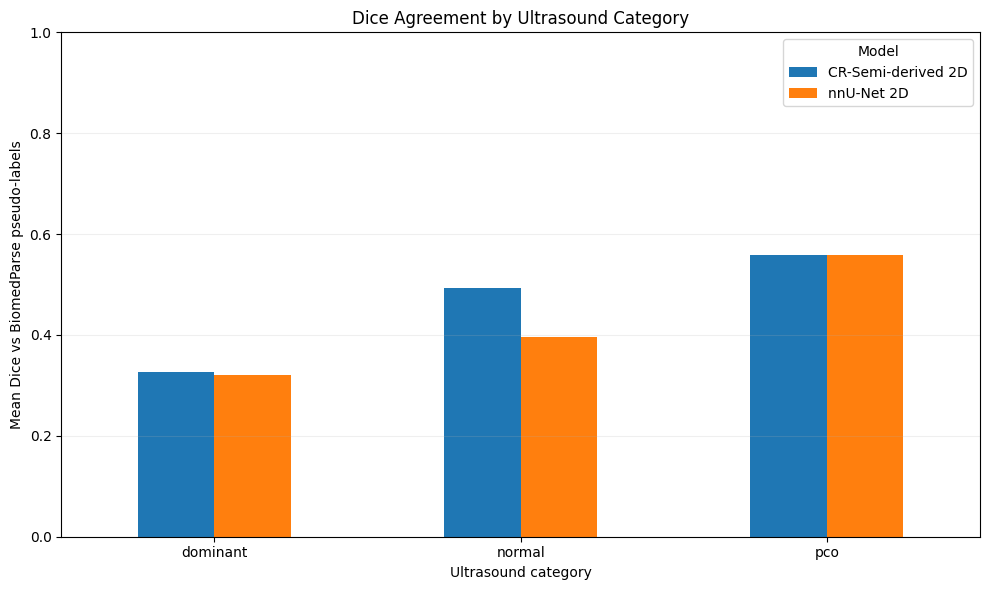

Saved table: /content/drive/MyDrive/ovarian_ultrasound_vlm/evaluation/cross_model/quantitative/segmentation_metrics_by_category.csv
Saved figure: /content/drive/MyDrive/ovarian_ultrasound_vlm/evaluation/cross_model/quantitative/segmentation_dice_by_category.png


In [11]:
# Compare segmentation agreement across ultrasound categories.

import pandas as pd
import matplotlib.pyplot as plt

CATEGORY_ORDER = ["dominant", "normal", "pco"]

category_summary = (
    metrics_df
    .groupby(["model", "category"], as_index=False)
    .agg(
        images=("case_id", "count"),
        mean_dice=("dice", "mean"),
        mean_iou=("iou", "mean"),
        mean_precision=("precision", "mean"),
        mean_recall=("recall", "mean")
    )
)

category_summary["category"] = pd.Categorical(
    category_summary["category"],
    categories=CATEGORY_ORDER,
    ordered=True
)

category_summary = category_summary.sort_values(
    ["category", "model"]
).reset_index(drop=True)

print("Category-wise segmentation agreement:")
display(category_summary.round(4))

# Save category-level results.
CATEGORY_CSV = (
    QUANTITATIVE_DIR / "segmentation_metrics_by_category.csv"
)

category_summary.to_csv(CATEGORY_CSV, index=False)

# Plot Dice by image category.
plot_data = category_summary.pivot(
    index="category",
    columns="model",
    values="mean_dice"
)

ax = plot_data.plot(
    kind="bar",
    figsize=(10, 6),
    rot=0
)

ax.set_title("Dice Agreement by Ultrasound Category")
ax.set_xlabel("Ultrasound category")
ax.set_ylabel("Mean Dice vs BiomedParse pseudo-labels")
ax.set_ylim(0, 1)
ax.legend(title="Model")
ax.grid(axis="y", alpha=0.2)

plt.tight_layout()

CATEGORY_FIGURE = (
    QUANTITATIVE_DIR / "segmentation_dice_by_category.png"
)

plt.savefig(
    CATEGORY_FIGURE,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

print("Saved table:", CATEGORY_CSV)
print("Saved figure:", CATEGORY_FIGURE)

Analyze Dice and IoU agreement with BiomedParse pseudo-labels
separately for dominant, normal, and PCO ultrasound images.

This analysis is descriptive and exploratory. The validation groups
contain different numbers of images, and pseudo-labels are not
expert ground truth.

In [12]:
# Compare exact PCO Dice values for both segmentation models.

pco_results = category_summary.loc[
    category_summary["category"] == "pco",
    ["model", "images", "mean_dice", "mean_iou"]
].copy()

print("Exact PCO results:")
print(pco_results.to_string(index=False, float_format="%.6f"))

Exact PCO results:
             model  images  mean_dice  mean_iou
CR-Semi-derived 2D      21   0.559264  0.460477
        nnU-Net 2D      21   0.559024  0.462034


PCO images: 21
Higher Dice for CR-Semi: 12
Higher Dice for nnU-Net: 8
Nearly identical Dice: 1
Mean paired Dice difference: 0.00024
Mean absolute Dice difference: 0.081012


model,case_id,CR-Semi-derived 2D,nnU-Net 2D,dice_difference
13,pco_0066,0.8138,0.5639,0.2499
5,pco_0040,0.3463,0.1795,0.1668
2,pco_0018,0.6938,0.5626,0.1312
3,pco_0036,0.2852,0.2166,0.0686
11,pco_0056,0.7783,0.7189,0.0593
10,pco_0054,0.9432,0.8865,0.0567
9,pco_0053,0.8979,0.8557,0.0423
16,pco_0096,0.7846,0.7482,0.0363
12,pco_0058,0.9525,0.9242,0.0283
0,pco_0002,0.9462,0.9374,0.0088


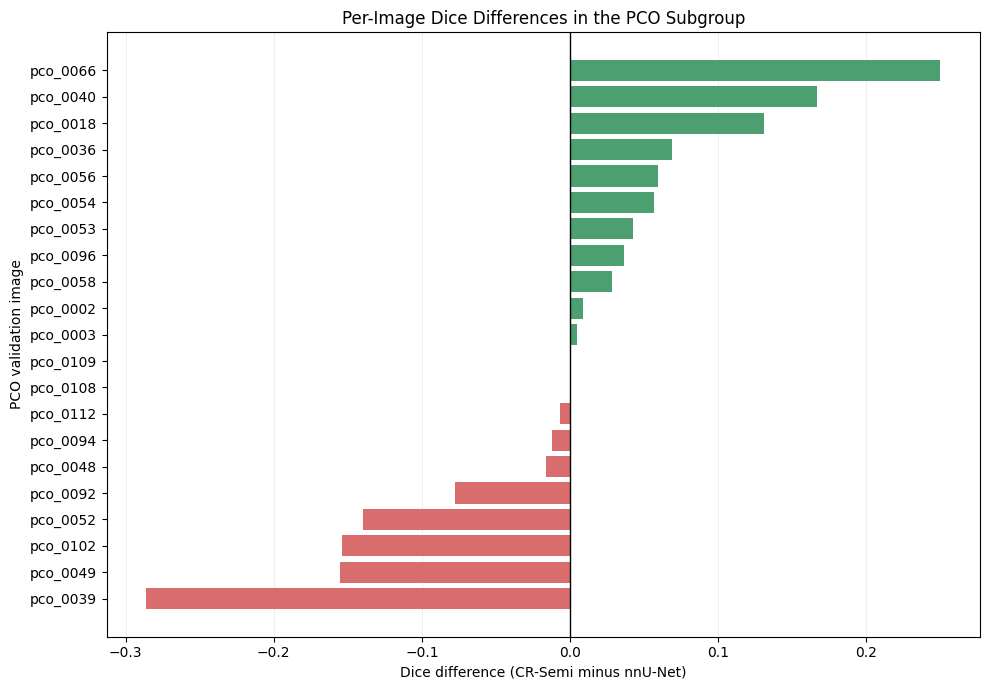

Saved table: /content/drive/MyDrive/ovarian_ultrasound_vlm/evaluation/cross_model/quantitative/pco_per_image_dice_comparison.csv
Saved figure: /content/drive/MyDrive/ovarian_ultrasound_vlm/evaluation/cross_model/quantitative/pco_per_image_dice_differences.png


In [13]:
# Compare per-image Dice agreement between nnU-Net and CR-Semi in PCO.

import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# Select PCO images from the existing quantitative results.
pco_df = metrics_df.loc[
    metrics_df["category"] == "pco",
    ["case_id", "model", "dice"]
].copy()

# Put both model scores on the same row for each image.
pco_paired = pco_df.pivot(
    index="case_id",
    columns="model",
    values="dice"
).reset_index()

assert len(pco_paired) == 21
assert pco_paired[
    ["nnU-Net 2D", "CR-Semi-derived 2D"]
].notna().all().all()

# Positive difference means higher agreement for CR-Semi.
pco_paired["dice_difference"] = (
    pco_paired["CR-Semi-derived 2D"]
    - pco_paired["nnU-Net 2D"]
)

pco_paired = pco_paired.sort_values(
    "dice_difference",
    ascending=False
)

# Calculate descriptive statistics.
crsemi_higher = int((pco_paired["dice_difference"] > 1e-6).sum())
nnunet_higher = int((pco_paired["dice_difference"] < -1e-6).sum())
tied = int((pco_paired["dice_difference"].abs() <= 1e-6).sum())

print("PCO images:", len(pco_paired))
print("Higher Dice for CR-Semi:", crsemi_higher)
print("Higher Dice for nnU-Net:", nnunet_higher)
print("Nearly identical Dice:", tied)
print(
    "Mean paired Dice difference:",
    round(pco_paired["dice_difference"].mean(), 6)
)
print(
    "Mean absolute Dice difference:",
    round(pco_paired["dice_difference"].abs().mean(), 6)
)

display(pco_paired.round(4))

# Save per-image results.
PCO_COMPARISON_CSV = (
    QUANTITATIVE_DIR / "pco_per_image_dice_comparison.csv"
)

pco_paired.to_csv(PCO_COMPARISON_CSV, index=False)

# Visualize paired differences.
plot_df = pco_paired.sort_values("dice_difference")

fig, ax = plt.subplots(figsize=(10, 7))

ax.barh(
    plot_df["case_id"],
    plot_df["dice_difference"],
    color=[
        "#4C9F70" if value > 0 else "#D96C6C"
        for value in plot_df["dice_difference"]
    ]
)

ax.axvline(0, color="black", linewidth=1)

ax.set_xlabel(
    "Dice difference (CR-Semi minus nnU-Net)"
)
ax.set_ylabel("PCO validation image")
ax.set_title("Per-Image Dice Differences in the PCO Subgroup")

ax.grid(axis="x", alpha=0.2)
ax.set_axisbelow(True)

plt.tight_layout()

PCO_COMPARISON_FIGURE = (
    QUANTITATIVE_DIR / "pco_per_image_dice_differences.png"
)

fig.savefig(
    PCO_COMPARISON_FIGURE,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

print("Saved table:", PCO_COMPARISON_CSV)
print("Saved figure:", PCO_COMPARISON_FIGURE)


Compare nnU-Net 2D and CR-Semi-derived 2D on the same 21 PCO
validation images.

Calculate paired Dice differences to determine whether similar
mean scores conceal differences at the individual-image level.

Dice scores measure agreement with BiomedParse pseudo-labels,
not expert-validated segmentation accuracy.

Bars to the right of zero — CR-Semi achieves a higher Dice score compared to BiomedParse.
Bars to the left of zero — nnU-Net achieves a higher Dice score.
Bars near zero — the models show similar performance on a given image.

Green bars — CR-Semi has a higher Dice score compared to BiomedParse.
Red bars — nnU-Net has a higher Dice score.

In [14]:
# Summarize paired Dice differences in the PCO subgroup.

differences = pco_paired["dice_difference"]

print("PCO images:", len(differences))
print("CR-Semi higher:", (differences > 1e-6).sum())
print("nnU-Net higher:", (differences < -1e-6).sum())
print("Nearly identical:", (differences.abs() <= 1e-6).sum())

print("Mean Dice difference:", round(differences.mean(), 6))
print("Mean absolute Dice difference:", round(differences.abs().mean(), 6))
print("Maximum absolute difference:", round(differences.abs().max(), 6))

PCO images: 21
CR-Semi higher: 12
nnU-Net higher: 8
Nearly identical: 1
Mean Dice difference: 0.00024
Mean absolute Dice difference: 0.081012
Maximum absolute difference: 0.286034


Figure saved: /content/drive/MyDrive/ovarian_ultrasound_vlm/figures/cross_model_comparison/pco_segmentation_case_comparison.png


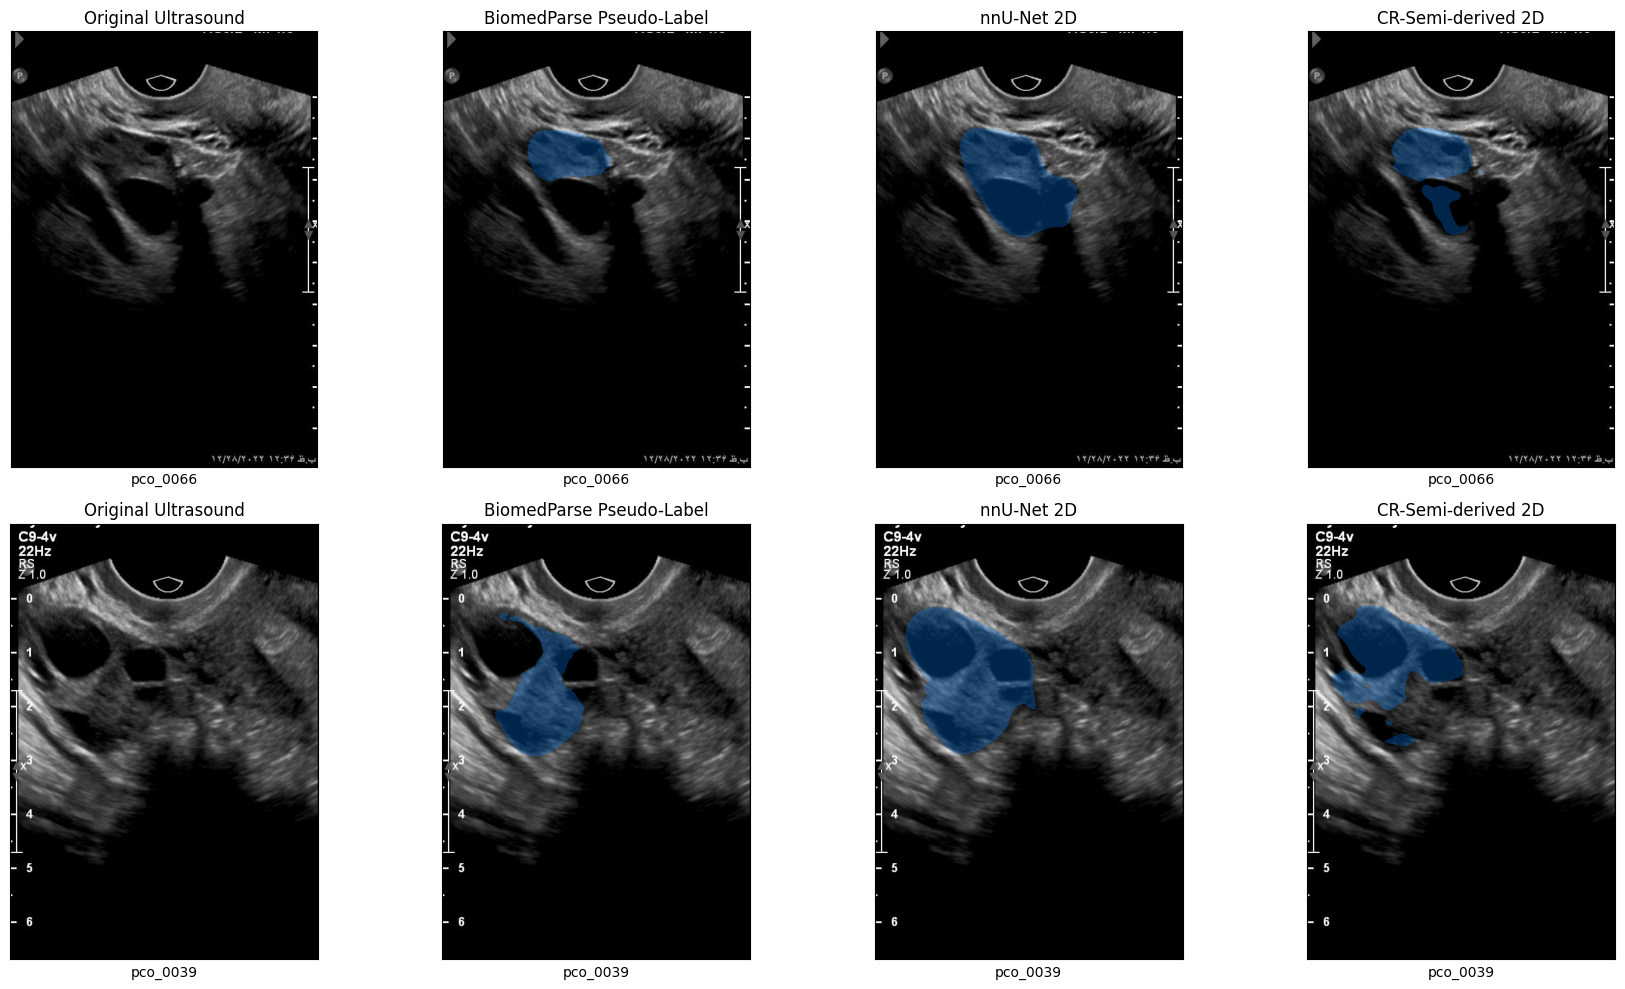

In [15]:
# Visualize PCO cases with contrasting segmentation results.

import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path
from PIL import Image

CASE_IDS = ["pco_0066", "pco_0039"]

NNUNET_DIR = PROJECT_DIR / "predictions" / "nnunet_2d_validation"
CRSEMI_DIR = PROJECT_DIR / "predictions" / "crsemi_2d_validation"

FIGURE_DIR = (
    PROJECT_DIR / "figures"
    / "cross_model_comparison"
)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

fig, axes = plt.subplots(2, 4, figsize=(18, 10))

titles = [
    "Original Ultrasound",
    "BiomedParse Pseudo-Label",
    "nnU-Net 2D",
    "CR-Semi-derived 2D"
]

for row_idx, case_id in enumerate(CASE_IDS):

    record = validation.loc[
        validation["case_id"] == case_id
    ]

    assert len(record) == 1, case_id

    record = record.iloc[0]

    image = np.asarray(
        Image.open(record["image_path"]).convert("RGB")
    )

    masks = [
        None,
        np.asarray(Image.open(record["pseudo_label_path"])),
        np.asarray(Image.open(NNUNET_DIR / f"{case_id}.png")),
        np.asarray(Image.open(CRSEMI_DIR / f"{case_id}.png"))
    ]

    for col_idx, mask in enumerate(masks):

        ax = axes[row_idx, col_idx]
        ax.imshow(image)

        if mask is not None:
            assert mask.shape == image.shape[:2], case_id

            overlay = np.zeros(
                (*mask.shape, 4),
                dtype=np.float32
            )

            foreground = mask == 1

            overlay[foreground, :3] = [0.0, 0.5, 1.0]
            overlay[foreground, 3] = 0.30

            ax.imshow(overlay)

        ax.set_title(titles[col_idx], fontsize=12)
        ax.set_xlabel(case_id)
        ax.set_xticks([])
        ax.set_yticks([])

plt.tight_layout()

FIGURE_PATH = (
    FIGURE_DIR / "pco_segmentation_case_comparison.png"
)

if FIGURE_PATH.exists():
    print("Existing figure preserved:", FIGURE_PATH)
else:
    fig.savefig(
        FIGURE_PATH,
        dpi=300,
        bbox_inches="tight"
    )
    print("Figure saved:", FIGURE_PATH)

plt.show()
plt.close(fig)

Visualize two PCO validation cases with substantial differences
in Dice agreement between nnU-Net 2D and CR-Semi-derived 2D.

Compare the original ultrasound, BiomedParse pseudo-label,
nnU-Net prediction, and CR-Semi-derived prediction.

These examples illustrate differences in pseudo-label agreement,
not independently verified segmentation accuracy.

Only two cases (pco_0066 and pco_0039) are selected because they show the most notable differences between CR-Semi and nnU-Net in opposite directions.

In [17]:
# Generate five-panel comparisons for all four models.

import json
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches

from pathlib import Path
from PIL import Image

# Define saved prediction directories.
GEMINI_PRED_DIR = (
    PROJECT_DIR / "predictions" / "main_validation"
)

NNUNET_PRED_DIR = (
    PROJECT_DIR / "predictions" / "nnunet_2d_validation"
)

CRSEMI_PRED_DIR = (
    PROJECT_DIR / "predictions" / "crsemi_2d_validation"
)

# Use a new directory to preserve previous figures.
ALL_MODELS_FIGURE_DIR = (
    PROJECT_DIR
    / "figures"
    / "cross_model_comparison"
    / "all_four_models"
)

ALL_MODELS_FIGURE_DIR.mkdir(
    parents=True,
    exist_ok=True
)

assert len(validation) == 61
assert validation["case_id"].is_unique


def add_mask_overlay(ax, image, mask):
    """Display a binary segmentation mask over the original image."""

    assert mask.shape == image.shape[:2]
    assert np.isin(mask, [0, 1]).all()

    ax.imshow(image)

    overlay = np.zeros(
        (*mask.shape, 4),
        dtype=np.float32
    )

    foreground = mask == 1

    overlay[foreground, :3] = [0.0, 0.5, 1.0]
    overlay[foreground, 3] = 0.30

    ax.imshow(overlay)


def add_gemini_boxes(ax, image, regions):
    """Display Gemini boxes using the original 0–1000 coordinates."""

    height, width = image.shape[:2]

    ax.imshow(image)

    for region in regions:

        x1, y1, x2, y2 = region["bbox"]

        assert 0 <= x1 < x2 <= 1000
        assert 0 <= y1 < y2 <= 1000

        xmin = x1 / 1000 * width
        ymin = y1 / 1000 * height
        xmax = x2 / 1000 * width
        ymax = y2 / 1000 * height

        rect = patches.Rectangle(
            (xmin, ymin),
            xmax - xmin,
            ymax - ymin,
            linewidth=2,
            edgecolor="lime",
            facecolor="none"
        )

        ax.add_patch(rect)


panel_titles = [
    "Original Ultrasound",
    "Gemini",
    "BiomedParse",
    "nnU-Net 2D",
    "CR-Semi-derived 2D"
]

for row in validation.itertuples(index=False):

    case_id = row.case_id

    output_path = (
        ALL_MODELS_FIGURE_DIR
        / f"{case_id}_comparison.png"
    )

    # Do not overwrite previously generated figures.
    if output_path.exists():
        continue

    # Load the original ultrasound.
    image = np.asarray(
        Image.open(row.image_path).convert("RGB")
    )

    # Load the saved Gemini annotation.
    gemini_path = GEMINI_PRED_DIR / f"{case_id}.json"

    assert gemini_path.is_file(), gemini_path

    with open(gemini_path, "r", encoding="utf-8") as f:
        gemini_result = json.load(f)

    gemini_annotation = gemini_result["annotation"]
    gemini_regions = gemini_annotation["regions"]

    assert len(gemini_regions) == int(
        gemini_annotation["follicle_like_count"]
    ), case_id

    # Load the three segmentation masks.
    mask_paths = [
        Path(row.pseudo_label_path),
        NNUNET_PRED_DIR / f"{case_id}.png",
        CRSEMI_PRED_DIR / f"{case_id}.png"
    ]

    masks = []

    for mask_path in mask_paths:

        assert mask_path.is_file(), mask_path

        mask = np.asarray(Image.open(mask_path))

        assert mask.shape == image.shape[:2], case_id
        assert np.isin(mask, [0, 1]).all(), case_id

        masks.append(mask)

    # Create five panels.
    fig, axes = plt.subplots(
        1, 5,
        figsize=(25, 6),
        constrained_layout=True
    )

    # Panel 1: Original ultrasound.
    axes[0].imshow(image)

    # Panel 2: Gemini bounding boxes.
    add_gemini_boxes(
        axes[1],
        image,
        gemini_regions
    )

    # Panels 3–5: Segmentation masks.
    for ax, mask in zip(axes[2:], masks):
        add_mask_overlay(ax, image, mask)

    for ax, title in zip(axes, panel_titles):
        ax.set_title(title, fontsize=13)
        ax.axis("off")

    fig.suptitle(
        f"{case_id} | Category: {row.category}",
        fontsize=16
    )

    fig.savefig(
        output_path,
        dpi=180,
        bbox_inches="tight"
    )

    plt.close(fig)

# Verify all expected figures.
expected_files = {
    f"{case_id}_comparison.png"
    for case_id in validation["case_id"]
}

actual_files = {
    path.name
    for path in ALL_MODELS_FIGURE_DIR.glob("*_comparison.png")
}

assert actual_files == expected_files, (
    f"Missing figures: {expected_files - actual_files}; "
    f"Unexpected figures: {actual_files - expected_files}"
)

print("Five-panel comparison figures:", len(actual_files))
print("Saved to:", ALL_MODELS_FIGURE_DIR)

Five-panel comparison figures: 61
Saved to: /content/drive/MyDrive/ovarian_ultrasound_vlm/figures/cross_model_comparison/all_four_models


Generate five-panel visualizations for all 61 validation images:

1. Original ultrasound
2. Gemini bounding-box predictions
3. BiomedParse pseudo-labels
4. nnU-Net 2D segmentation predictions
5. CR-Semi-derived 2D segmentation predictions

Gemini bounding boxes use the original normalized coordinate system
(0–1000). Segmentation masks are displayed as semi-transparent overlays.

These visualizations support descriptive comparison and do not
establish expert-validated segmentation accuracy.